<a href="https://colab.research.google.com/github/mohammedkhadirkhadrijk8-max/LSTM-model-for-IMDB-dataset/blob/main/deep_learning_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


313/313 ━━━━━━━━━━━━━━━━━━━━ 87s 270ms/step - accuracy: 0.7850 - loss: 0.4539 - val_accuracy: 0.8630 - val_loss: 0.3412
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 84s 268ms/step - accuracy: 0.8986 - loss: 0.2562 - val_accuracy: 0.8774 - val_loss: 0.3123
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 262ms/step - accuracy: 0.9312 - loss: 0.1850 - val_accuracy: 0.8780 - val_loss: 0.3413
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 262ms/step - accuracy: 0.9511 - loss: 0.1368 - val_accuracy: 0.8496 - val_loss: 0.3985
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 82s 263ms/step - accuracy: 0.9584 - loss: 0.1121 - val_accuracy: 0.8660 - val_loss: 0.3971

Test Accuracy: 0.8603


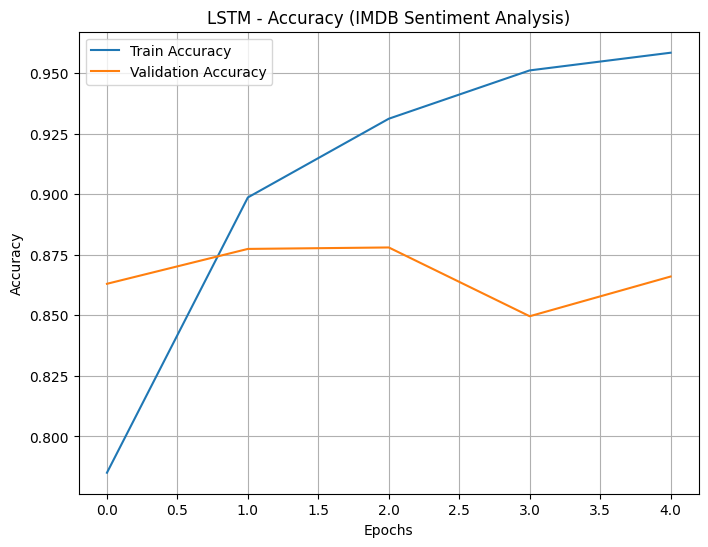

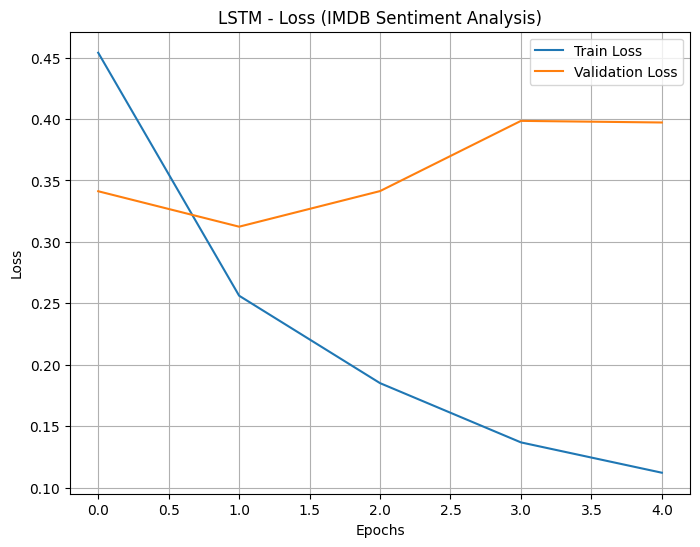

782/782 ━━━━━━━━━━━━━━━━━━━━ 27s 34ms/step


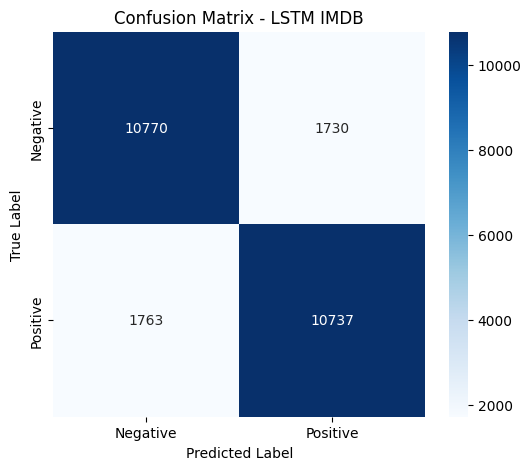


Classification Report - LSTM IMDB
              precision    recall  f1-score   support

    Negative       0.86      0.86      0.86     12500
    Positive       0.86      0.86      0.86     12500

    accuracy                           0.86     25000
   macro avg       0.86      0.86      0.86     25000
weighted avg       0.86      0.86      0.86     25000



In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
# 1. Load IMDB dataset
max_features = 10000 # Vocabulary size
max_len = 200 # Sequence length
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(num_words=max_features)
# Pad sequences to ensure equal length
x_train = tf.keras.preprocessing.sequence.pad_sequences(x_train, maxlen=max_len)
x_test = tf.keras.preprocessing.sequence.pad_sequences(x_test, maxlen=max_len)
# 2. Build LSTM Model
model = models.Sequential([
layers.Embedding(input_dim=max_features, output_dim=128, input_length=max_len),
layers.LSTM(64, return_sequences=False),
layers.Dense(1, activation='sigmoid')
])
model.compile(optimizer='adam',
loss='binary_crossentropy',
metrics=['accuracy'])
# 3. Train Model
history = model.fit(
x_train, y_train,
validation_split=0.2,
epochs=5,
batch_size=64,
verbose=1
)
# 4. Evaluate Model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest Accuracy: {test_acc:.4f}")
# 5. Plot Accuracy
plt.figure(figsize=(8, 6))
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title("LSTM - Accuracy (IMDB Sentiment Analysis)")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 6. Plot Loss
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("LSTM - Loss (IMDB Sentiment Analysis)")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()
# 7. Predictions
y_pred_probs = model.predict(x_test)
y_pred = (y_pred_probs > 0.5).astype("int32").flatten()
y_true = y_test.flatten()
# 8. Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
xticklabels=['Negative', 'Positive'],
yticklabels=['Negative', 'Positive'])
plt.title("Confusion Matrix - LSTM IMDB")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()
# 9. Classification Report
print("\nClassification Report - LSTM IMDB")
print(classification_report(y_true, y_pred, target_names=['Negative', 'Positive']))